In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("dataset/train.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
X = df.drop(columns=["price_range", "id"], errors="ignore")
y = df["price_range"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (2000, 20)
Target Shape: (2000,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1600, 20)
Testing Data: (400, 20)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (1600, 20)
Scaled Testing Shape: (400, 20)


In [6]:
X_train_lstm = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_test_lstm = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("LSTM Training Shape:", X_train_lstm.shape)
print("LSTM Testing Shape:", X_test_lstm.shape)

LSTM Training Shape: (1600, 20, 1)
LSTM Testing Shape: (400, 20, 1)


In [7]:
model = Sequential([
    Input(shape=(20, 1)),
    LSTM(32, activation="tanh"),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,948 (19.33 KB)

 Trainable params: 4,948 (19.33 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("LSTM Model Compiled Successfully!")

LSTM Model Compiled Successfully!


In [9]:
history = model.fit(
    X_train_lstm,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3242 - loss: 1.3737 - val_accuracy: 0.3313 - val_loss: 1.3655
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3555 - loss: 1.3393 - val_accuracy: 0.3344 - val_loss: 1.3325
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3750 - loss: 1.3130 - val_accuracy: 0.3250 - val_loss: 1.3127
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3867 - loss: 1.2915 - val_accuracy: 0.3625 - val_loss: 1.2941
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3969 - loss: 1.2749 - val_accuracy: 0.3875 - val_loss: 1.2766
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4109 - loss: 1.2604 - val_accuracy: 0.3844 - val_loss: 1.2609
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4227 - loss: 1.2520 - val_accuracy: 0.3938 - val_loss: 1.2511
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4180 - loss: 1.2513 - val_accuracy: 0.4062 - val_loss

In [10]:
y_probability = model.predict(X_test_lstm)
y_pred = np.argmax(y_probability, axis=1)

print("Actual Values:   ", y_test.values[:10])
print("Predicted Values:", y_pred[:10])

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Actual Values:    [3 1 0 2 3 2 0 0 1 0]
Predicted Values: [3 2 1 2 3 3 1 0 0 0]


In [11]:
accuracy = accuracy_score(y_test, y_pred)

print("LSTM Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

LSTM Model Accuracy: 41.5 %

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.49      0.50       100
           1       0.29      0.30      0.30       100
           2       0.28      0.22      0.25       100
           3       0.52      0.65      0.58       100

    accuracy                           0.41       400
   macro avg       0.40      0.42      0.41       400
weighted avg       0.40      0.41      0.41       400



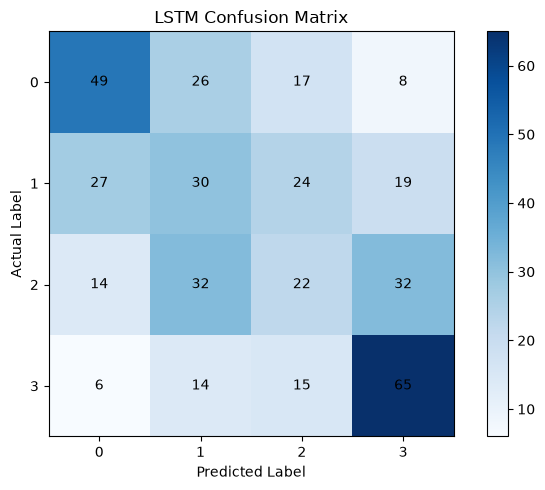

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1, 2, 3])
plt.yticks([0, 1, 2, 3])

for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

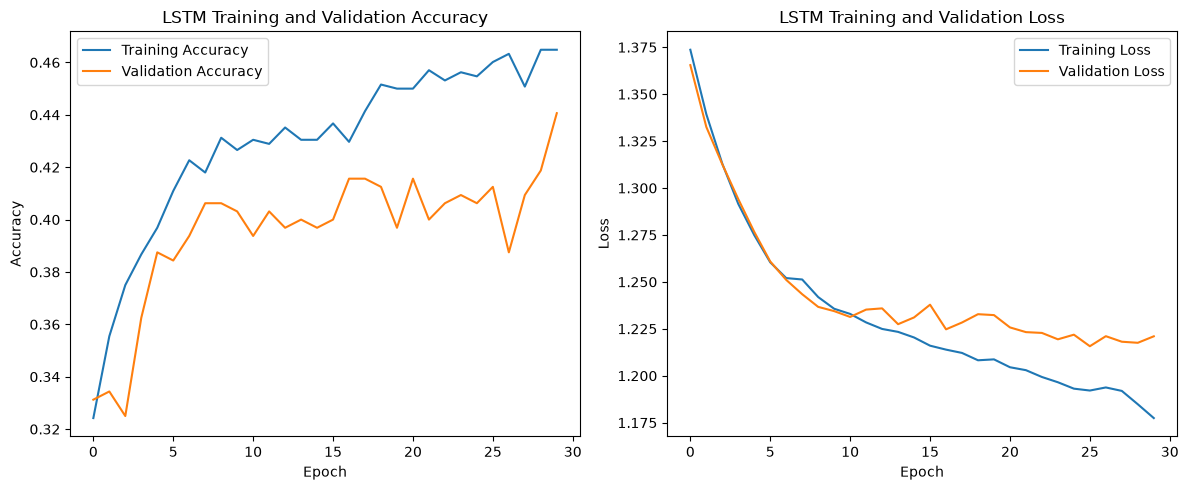

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()